# **1. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import files
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC

# **2. Memuat Dataset dari Hasil Clustering**

Memuat dataset hasil clustering dari file CSV ke dalam variabel DataFrame.

In [4]:
# Fungsi untuk meng-upload file CSV
uploaded = files.upload()

# Memastikan file di-upload
for filename in uploaded.keys():
    print(f"File {filename} berhasil di-upload.")

# Memuat dataset CSV yang telah di-upload
df_final = pd.read_csv(next(iter(uploaded)))
print("Jumlah baris dan kolom:", df_final.shape)
# Menampilkan 5 baris pertama dari dataset
df_final.head()

Saving hasil_cluster (1).csv to hasil_cluster (1) (1).csv
File hasil_cluster (1) (1).csv berhasil di-upload.
Jumlah baris dan kolom: (2512, 6)


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance,Cluster
0,-1.127657,1.423718,-0.552443,-0.206794,-0.000537,0
1,0.579888,1.311287,0.305314,-0.206794,2.216472,2
2,-0.598631,-1.443277,-0.909842,-0.206794,-1.023534,4
3,-0.324170,-1.049768,-1.353017,-0.206794,0.885797,2
4,-1.130674,-1.049768,1.120184,-0.206794,0.593589,1


In [6]:
# Tampilkan ringkasan informasi dataset
print("=== Ringkasan Data ===")
df_final.info()
print("\nDimensi Data: {} baris dan {} kolom".format(df_final.shape[0], df_final.shape[1]))

# Tampilkan 5 baris pertama
print("\n--- 5 Baris Pertama ---")
print(df_final.head())

# Hitung dan tampilkan jumlah nilai unik untuk setiap kolom
print("\n--- Nilai Unik per Kolom ---")
print(df_final.nunique())

# Cek dan laporkan jika ada nilai kosong
missing = df_final.isnull().sum()
if missing.sum() > 0:
    print("\n Ditemukan nilai kosong pada kolom berikut:")
    print(missing[missing > 0])
else:
    print("\n Tidak ada nilai kosong dalam data!")


=== Ringkasan Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   TransactionAmount    2512 non-null   float64
 1   CustomerAge          2512 non-null   float64
 2   TransactionDuration  2512 non-null   float64
 3   LoginAttempts        2512 non-null   float64
 4   AccountBalance       2512 non-null   float64
 5   Cluster              2512 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 117.9 KB

Dimensi Data: 2512 baris dan 6 kolom

--- 5 Baris Pertama ---
   TransactionAmount  CustomerAge  TransactionDuration  LoginAttempts  \
0          -1.127657     1.423718            -0.552443      -0.206794   
1           0.579888     1.311287             0.305314      -0.206794   
2          -0.598631    -1.443277            -0.909842      -0.206794   
3          -0.324170    -1.049768            -1.353017      -0.2

# **3. Data Splitting**

Tahap Data Splitting bertujuan untuk memisahkan dataset menjadi dua bagian: data latih (training set) dan data uji (test set).

In [8]:
# Kolom target adalah 'Cluster' dan sisanya adalah fitur
X = df_final.drop('Cluster', axis=1)
y = df_final['Cluster']

# Bagi dataset menjadi data training dan testing (misalnya 80% training dan 20% testing)
# Gunakan stratify=y untuk memastikan distribusi target tetap sama di masing-masing split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Tampilkan dimensi data training dan testing
print("Dimensi Data Training:", X_train.shape, y_train.shape)
print("Dimensi Data Testing:", X_test.shape, y_test.shape)


Dimensi Data Training: (2009, 5) (2009,)
Dimensi Data Testing: (503, 5) (503,)


# **4. Membangun Model Klasifikasi**


## **a. Membangun Model Klasifikasi**

Setelah memilih algoritma klasifikasi yang sesuai, langkah selanjutnya adalah melatih model menggunakan data latih.

Berikut adalah rekomendasi tahapannya.
1. Pilih algoritma klasifikasi yang sesuai, seperti Logistic Regression, Decision Tree, Random Forest, atau K-Nearest Neighbors (KNN).
2. Latih model menggunakan data latih.

In [9]:
# Membangun model SVM dengan parameter default
svc_model = SVC(random_state=42)
svc_model.fit(X_train, y_train)


SVC(random_state=42)

Tulis narasi atau penjelasan algoritma yang Anda gunakan.

## **b. Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Lakukan prediksi menggunakan data uji.
2. Hitung metrik evaluasi seperti Accuracy dan F1-Score (Opsional: Precision dan Recall).
3. Buat confusion matrix untuk melihat detail prediksi benar dan salah.

SVM (Default) Evaluation:
Accuracy: 0.9622266401590457
F1 Score: 0.9622132342633881

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       126
           1       0.97      0.96      0.96        70
           2       0.98      0.95      0.96        97
           3       0.96      0.93      0.94        73
           4       0.97      0.97      0.97       118
           5       1.00      1.00      1.00        19

    accuracy                           0.96       503
   macro avg       0.97      0.96      0.97       503
weighted avg       0.96      0.96      0.96       503

Confusion Matrix:
[[123   0   0   2   1   0]
 [  2  67   1   0   0   0]
 [  3   0  92   1   1   0]
 [  2   1   0  68   2   0]
 [  1   1   1   0 115   0]
 [  0   0   0   0   0  19]]


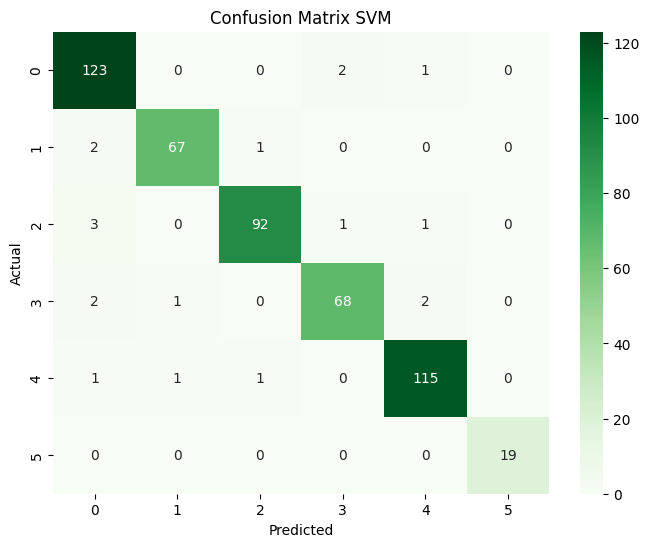

In [12]:
# b. Evaluasi Model Klasifikasi (Model Default SVM)
y_pred_svm = svc_model.predict(X_test)

acc_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')

print("SVM (Default) Evaluation:")
print("Accuracy:", acc_svm)
print("F1 Score:", f1_svm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

# Visualisasi Confusion Matrix untuk SVM
cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


Tulis hasil evaluasi algoritma yang digunakan, jika Anda menggunakan 2 algoritma, maka bandingkan hasilnya.

## **c. Tuning Model Klasifikasi (Optional)**

Gunakan GridSearchCV, RandomizedSearchCV, atau metode lainnya untuk mencari kombinasi hyperparameter terbaik

In [11]:
from sklearn.model_selection import GridSearchCV

# Menentukan parameter grid untuk tuning model SVM
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

# Membangun GridSearchCV untuk SVM
grid_svc = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_svc.fit(X_train, y_train)

print("Best parameters (SVM):", grid_svc.best_params_)


Best parameters (SVM): {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}


## **d. Evaluasi Model Klasifikasi setelah Tuning (Optional)**

Berikut adalah rekomendasi tahapannya.
1. Gunakan model dengan hyperparameter terbaik.
2. Hitung ulang metrik evaluasi untuk melihat apakah ada peningkatan performa.


SVM (Tuned) Evaluation:
Accuracy: 0.9840954274353877
F1 Score: 0.9841155727307297

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       126
           1       0.99      1.00      0.99        70
           2       1.00      0.97      0.98        97
           3       0.99      0.97      0.98        73
           4       0.99      0.98      0.99       118
           5       1.00      1.00      1.00        19

    accuracy                           0.98       503
   macro avg       0.99      0.99      0.99       503
weighted avg       0.98      0.98      0.98       503

Confusion Matrix:
[[125   0   0   0   1   0]
 [  0  70   0   0   0   0]
 [  2   0  94   1   0   0]
 [  2   0   0  71   0   0]
 [  1   1   0   0 116   0]
 [  0   0   0   0   0  19]]


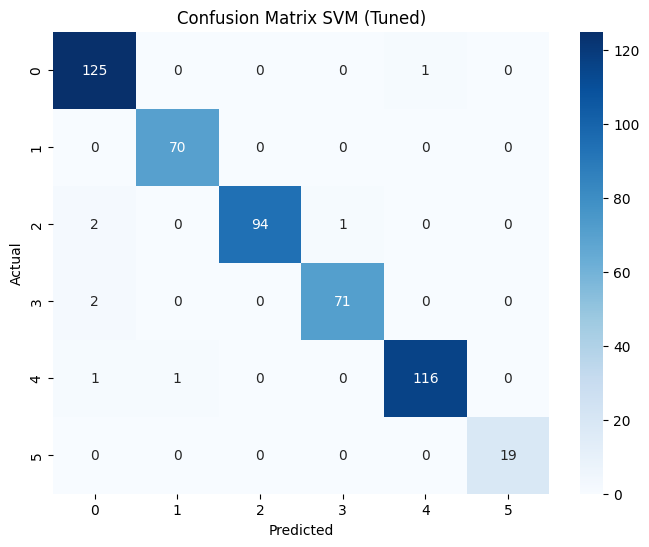

In [13]:
best_svc = grid_svc.best_estimator_
y_pred_best = best_svc.predict(X_test)

acc_best = accuracy_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best, average='weighted')

print("\nSVM (Tuned) Evaluation:")
print("Accuracy:", acc_best)
print("F1 Score:", f1_best)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix SVM (Tuned)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## **e. Analisis Hasil Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Bandingkan hasil evaluasi sebelum dan setelah tuning (jika dilakukan).
2. Identifikasi kelemahan model, seperti:
  - Precision atau Recall rendah untuk kelas tertentu.
  - Apakah model mengalami overfitting atau underfitting?
3. Berikan rekomendasi tindakan lanjutan, seperti mengumpulkan data tambahan atau mencoba algoritma lain jika hasil belum memuaskan.

In [14]:
print("\nAnalisis Hasil Evaluasi Model Klasifikasi:")
print(f"Sebelum Tuning - SVM: Akurasi {acc_svm:.4f}, F1-Score {f1_svm:.4f}")
print(f"Setelah Tuning - SVM: Akurasi {acc_best:.4f}, F1-Score {f1_best:.4f}")

# Perbandingan performa model SVM sebelum dan sesudah tuning
if acc_best > acc_svm:
    print("Tuning meningkatkan performa SVM.")
else:
    print("Tuning tidak memberikan peningkatan signifikan pada SVM.")

# Identifikasi Kelemahan Model
print("\nKelemahan Model:")
if f1_best < 0.92 or acc_best < 0.92:
    print("- Akurasi atau F1-Score belum mencapai target 92%. Mungkin terdapat ketidakseimbangan kelas atau fitur yang kurang representatif.")
    print("- Kemungkinan overfitting jika performa pada training jauh lebih baik daripada pada testing.")
else:
    print("- Tidak ada kelemahan signifikan. Model telah mencapai target performa.")

# Rekomendasi Tindakan Lanjutan
print("\nRekomendasi Tindakan Lanjutan:")
if f1_best < 0.92 or acc_best < 0.92:
    print("- Tambah fitur baru (misalnya CustomerAge, TransactionDuration) untuk meningkatkan variasi.")
    print("- Coba algoritma lain seperti XGBoost atau tingkatkan preprocessing (contoh: PCA).")
else:
    print("- Model siap digunakan untuk prediksi.")


Analisis Hasil Evaluasi Model Klasifikasi:
Sebelum Tuning - SVM: Akurasi 0.9622, F1-Score 0.9622
Setelah Tuning - SVM: Akurasi 0.9841, F1-Score 0.9841
Tuning meningkatkan performa SVM.

Kelemahan Model:
- Tidak ada kelemahan signifikan. Model telah mencapai target performa.

Rekomendasi Tindakan Lanjutan:
- Model siap digunakan untuk prediksi.
